### sprott_test10

Manual reconstruction of the Sprott B system and Merredin weather system through Taken's Embedding Theorem 

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1   
- #nahsivar. (2013). Optimal way to compute pairwise mutual information using numpy. Stack Overflow. https://stackoverflow.com/questions/20491028/optimal-way-to-compute-pairwise-mutual-information-using-numpy


-- Explored use of Mututal Information and Autocorrelation to calculate lag to be used in reconstruction
-- Attempted reconstruction of both Sprott B system and Merredin system 


--- Date:   September 2026

In [ ]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
import math
import statsmodels.api as sm
import numpy as np
from scipy.signal import find_peaks
from sklearn.metrics import mutual_info_score

In [ ]:
def collect_data(form,lat,lon,start,finish,username="email@gmail.com",password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')




In [ ]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)



In [ ]:
#Testing Rain against GDDc for Merreddin 

start_date = '19710101'
end_date = '20260327'

merre_data = collect_data('standard','-31.48','118.28',start_date,end_date)
merre_rain, merre_gddc = prepare_data(merre_data, by = "")

[[     0.]
 [   300.]
 [   600.]
 [   900.]
 [  1200.]
 [  1500.]
 [  1800.]
 [  2100.]
 [  2400.]
 [  2700.]
 [  3000.]
 [  3300.]
 [  3600.]
 [  3900.]
 [  4200.]
 [  4500.]
 [  4800.]
 [  5100.]
 [  5400.]
 [  5700.]
 [  6000.]
 [  6300.]
 [  6600.]
 [  6900.]
 [  7200.]
 [  7500.]
 [  7800.]
 [  8100.]
 [  8400.]
 [  8700.]
 [  9000.]
 [  9300.]
 [  9600.]
 [  9900.]
 [ 10200.]
 [ 10500.]
 [ 10800.]
 [ 11100.]
 [ 11400.]
 [ 11700.]
 [ 12000.]
 [ 12300.]
 [ 12600.]
 [ 12900.]
 [ 13200.]
 [ 13500.]
 [ 13800.]
 [ 14100.]
 [ 14400.]
 [ 14700.]
 [ 15000.]
 [ 15300.]
 [ 15600.]
 [ 15900.]
 [ 16200.]
 [ 16500.]
 [ 16800.]
 [ 17100.]
 [ 17400.]
 [ 17700.]
 [ 18000.]
 [ 18300.]
 [ 18600.]
 [ 18900.]
 [ 19200.]
 [ 19500.]
 [ 19800.]
 [ 20100.]
 [ 20400.]
 [ 20700.]
 [ 21000.]
 [ 21300.]
 [ 21600.]
 [ 21900.]
 [ 22200.]
 [ 22500.]
 [ 22800.]
 [ 23100.]
 [ 23400.]
 [ 23700.]
 [ 24000.]
 [ 24300.]
 [ 24600.]
 [ 24900.]
 [ 25200.]
 [ 25500.]
 [ 25800.]
 [ 26100.]
 [ 26400.]
 [ 26700.]
 [ 27000.]

In [6]:

def sprott_attractor(matrix, coef, constant):
    """
    sprott attractor B equations

    will vary coef (dxdt) and constant (dzdt)
    """
    x,y,z = matrix
    dxdt = coef*y*z
    dydt = x - y 
    dzdt = constant - x*y
    return np.array([dxdt, dydt, dzdt])

def rk4_sprott(x0, y0, z0, t0, tf, h, coef, constant):
    """
    4th order runge-kutta solver
    
    param x,y,z,0: initial value
    param t0: initial time
    param tf: final time
    param h: step size
    coef: coefficient value for dxdt
    constant: constant for dzdt
    """

    n = int((tf-t0)/h)
    original = np.array([x0,y0,z0])


    vals = [original] #list of all resulting values

    for i in range(n):

        k1 = sprott_attractor(original, coef, constant) * h
        k2 = sprott_attractor(original + k1/2,coef, constant) * h
        k3 = sprott_attractor(original + k2/2, coef, constant) * h
        k4 = sprott_attractor(original + k3, coef, constant) * h

        original = original + ((1/6)*(k1+2*k2+2*k3+k4))

        vals.append(original.copy())

    return np.array(vals)



When recreating an attractor, must determine:

- The lag - done through Mutual Information and Autocorrelation
- The number of embedding dimensions - NOT EXPLORED WITHIN THIS NOTEBOOK

### Comparing methods of deriving lag

In [ ]:
# example sprott B system
data = rk4_sprott(x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01, coef=0.5, constant=1)

# extracting variables x, y, z
x_vals = data[:,0]
y_vals = data[:,1]
z_vals = data[:,2]


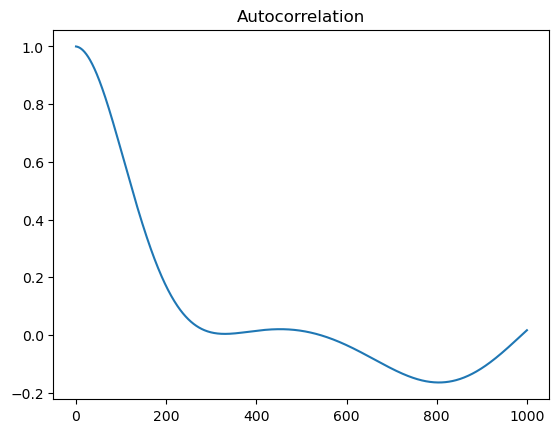

(array([541, 988]),)


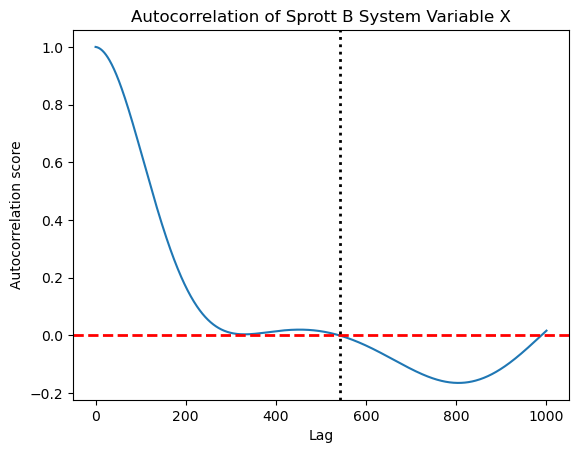

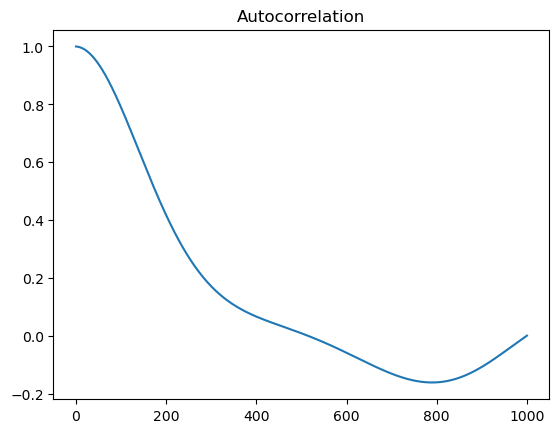

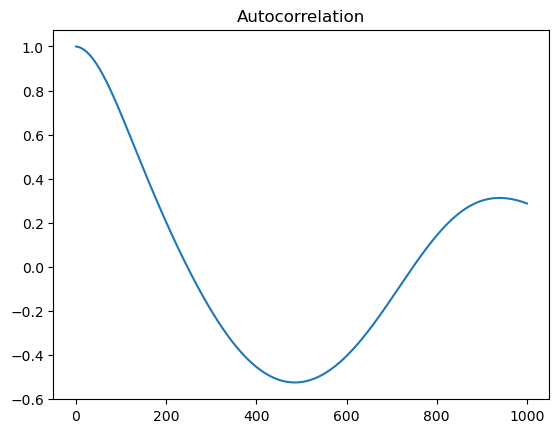

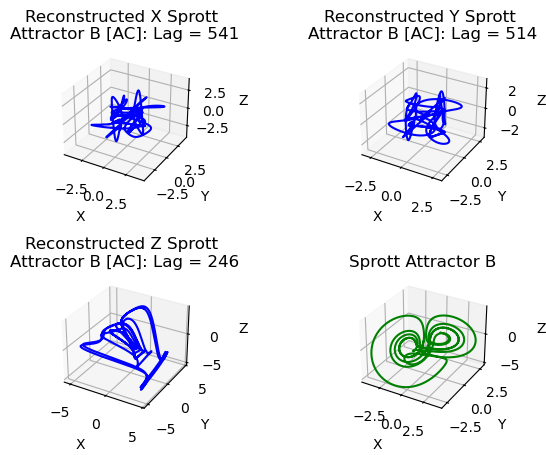

In [ ]:
# computing autocorrelation functions for each of the variables 

def calc_autocorr(vals):
    autocorrvalues = sm.tsa.acf(vals, nlags=1000) # calculate autocorrelation
    zero_val = np.where(np.diff(np.sign(autocorrvalues)) != 0) # find where the signs of the function first change (ie. the first zero-crossing)

    # adjust to first zero correlation
    plt.plot(autocorrvalues)
    plt.title("Autocorrelation")
    plt.show()

    tau = zero_val[0][0]
    return tau # first zero-crossing is the lag.


def compute_lags(vals, tau): # compute lags using taken's embedding theorem equations
    lag0 = vals[:-2*tau]
    lag1 = vals[tau:-tau]
    lag2 = vals[2*tau:]

    return lag0, lag1, lag2


x_tau = calc_autocorr(x_vals)
autocorrvalues = sm.tsa.acf(x_vals, nlags=1000)
zero_val = np.where(np.diff(np.sign(autocorrvalues)) != 0)
print(zero_val)

# plot autocorrelation function and first zero-crossing for the x-variable of Sprott B system
plt.plot(autocorrvalues)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.axvline(x=zero_val[0][0], color='black', linestyle=':', linewidth=2)
plt.title("Autocorrelation of Sprott B System Variable X")
plt.xlabel('Lag')
plt.ylabel('Autocorrelation score')
plt.savefig('Auto_Corr_plot.png')
plt.show()


# compute lags for each of the 3 variables
x_lag0, x_lag1, x_lag2 = compute_lags(x_vals, x_tau)

y_tau = calc_autocorr(y_vals)
y_lag0, y_lag1, y_lag2 = compute_lags(y_vals, y_tau)

z_tau = calc_autocorr(z_vals)
z_lag0, z_lag1, z_lag2 = compute_lags(z_vals, z_tau)


plots = [('X', x_lag0, x_lag1, x_lag2, x_tau),
         ('Y',y_lag0, y_lag1, y_lag2, y_tau),
         ('Z',z_lag0, z_lag1, z_lag2, z_tau)]

# using the theorem, reconstruction can attempt to occur with the 2 other lagged vectors. 
fig = plt.figure()
for i, (var, lag0, lag1, lag2, tau) in enumerate(plots, start=1):
    ax = fig.add_subplot(2,2,i, projection='3d')
    ax.plot3D(lag0, lag1, lag2, 'blue')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('Reconstructed ' + var + ' Sprott \nAttractor B [AC]: Lag = ' + str(tau))

# plot against the actual Sprott B system
ax = fig.add_subplot(224, projection='3d')
ax.plot3D(data[:-2*tau,0], data[:-2*tau,1], data[:-2*tau,2], 'green') # indexed so the the number of values match up with the last lag
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Sprott Attractor B')

fig.subplots_adjust(wspace=0.5, hspace=0.6)
plt.savefig('Sprott_Reconstruction[AC].png', dpi=100)





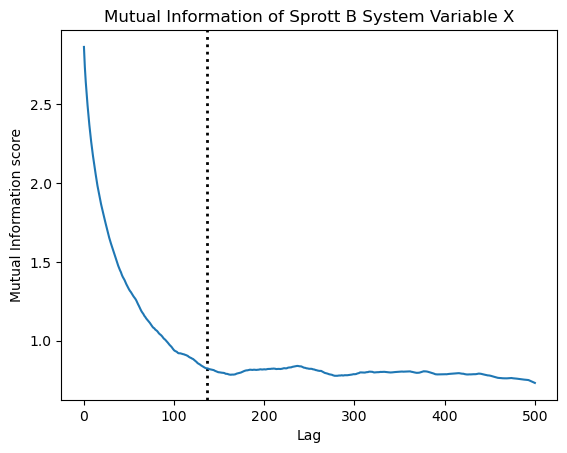

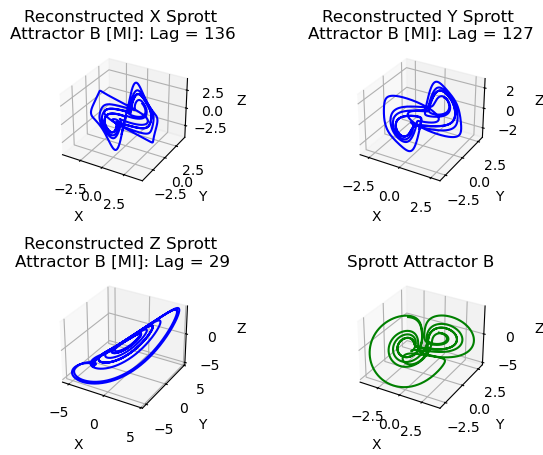

In [ ]:
# mutual information 
#nahsivar. (2013). Optimal way to compute pairwise mutual information using numpy. Stack Overflow. https://stackoverflow.com/questions/20491028/optimal-way-to-compute-pairwise-mutual-information-using-numpy

# compute mutual informaiton function of the input data
def mutual_information(original, lagged, bins=30):
    c_XY = np.histogram2d(original, lagged, bins)[0] # estimate the joint probability density distribution  
    mi = mutual_info_score(None, None, contingency=c_XY) # calculate mutual information scores using joint probability density distribution
    return mi


def calc_firstmin_and_lags(vals, max_tau):
    mis = []
    for tau in range(0, max_tau + 1): # given a tau, compute the lagged values 
        if tau == 0:
            unlagged = vals
            lagged = vals
        else:
            unlagged = vals[:-tau]
            lagged = vals[tau:]
        mi = mutual_information(unlagged, lagged) # compute mutual information between lagged and unlagged values
        mis.append(mi)



    mi_mins, _ = find_peaks(-np.array(mis)) # finding first minimum of Mutual Information
    min_tau = mi_mins[0] # assign as lag

    l_0 = vals[:-2*min_tau]
    l_1 = vals[min_tau:-min_tau]
    l_2 = vals[2*min_tau:]

    return l_0, l_1, l_2, min_tau, mis

x0, x1, x2, x_tau, mis = calc_firstmin_and_lags(x_vals,max_tau=500)
plt.axvline(x=x_tau, color='black', linestyle=':', linewidth=2)
plt.plot(mis)
plt.title("Mutual Information of Sprott B System Variable X")
plt.xlabel('Lag')
plt.ylabel('Mutual Information score')
plt.savefig('MI_plot.png')
plt.show()

y0, y1, y2, y_tau, mis = calc_firstmin_and_lags(y_vals,max_tau=500)
z0, z1, z2, z_tau, mis = calc_firstmin_and_lags(z_vals,max_tau=500)



mi_plots = [('X', x0, x1, x2, x_tau),
            ('Y', y0, y1, y2, y_tau),
            ('Z', z0, z1, z2, z_tau)]

fig = plt.figure()

for i, (var, lag0, lag1, lag2, tau) in enumerate(mi_plots, start=1):
    ax = fig.add_subplot(2,2,i, projection='3d')
    ax.plot3D(lag0, lag1, lag2, 'blue')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('Reconstructed ' + var + ' Sprott \nAttractor B [MI]: Lag = ' + str(tau))

ax = fig.add_subplot(224, projection='3d')
ax.plot3D(data[:-2*tau,0], data[:-2*tau,1], data[:-2*tau,2], 'green')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Sprott Attractor B')

fig.subplots_adjust(wspace=0.5, hspace=0.6)
plt.savefig('Sprott_Reconstruction[MI].png', dpi=100)





Reconstructing the Merredin system

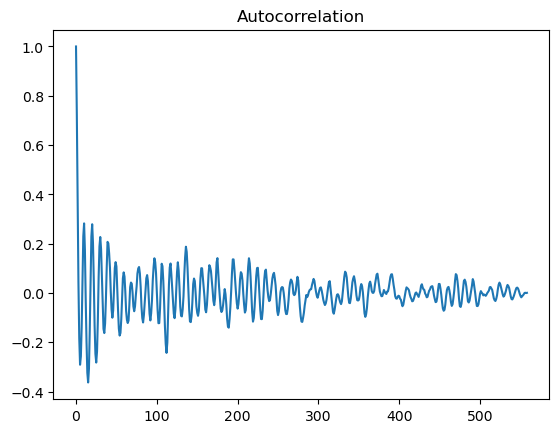

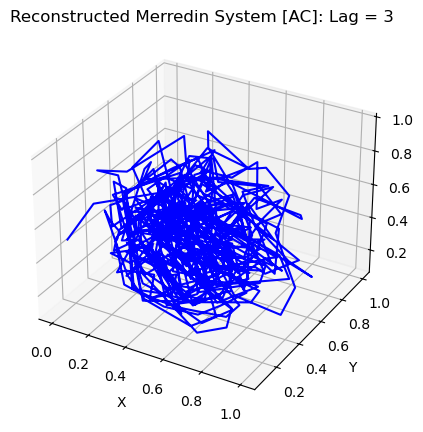

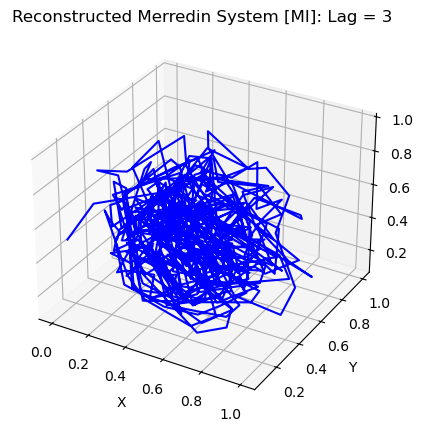

In [10]:
# Based on autocorrelation
m_tau = calc_autocorr(merre_rain)
m_lag0, m_lag1, m_lag2 = compute_lags(merre_rain, m_tau)


fig = plt.figure()
ax = fig.add_subplot(projection='3d')
fig.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
ax.plot3D(m_lag0, m_lag1, m_lag2, 'blue')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Reconstructed Merredin System [AC]: Lag = ' + str(m_tau))
plt.savefig('Merredin_Reconstructed[AC].png', dpi=100)


#Based on MI
m0, m1, m2, mtau, mis = calc_firstmin_and_lags(merre_rain.flatten(), max_tau=len(merre_rain)-1)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
fig.subplots_adjust(right=0.85)  # leave more room on the right for the z-label
ax.plot3D(m0, m1, m2, 'blue')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Reconstructed Merredin System [MI]: Lag = ' + str(mtau))
fig.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.savefig('Merredin_Reconstructed[MI].png', dpi=100)

